# DSCI 552 HW 8

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

warnings.filterwarnings("ignore")
RANDOM_STATE = 552

### 1a. load breast cancer data

In [ ]:
cols = ["id", "diagnosis"] + [f"f{i}" for i in range(1, 31)]
wdbc = pd.read_csv("../data/wdbc.data", header=None, names=cols)
X = wdbc.iloc[:, 2:].values
y = (wdbc["diagnosis"] == "M").astype(int).values
print(X.shape, "| malignant:", y.sum(), "| benign:", (y == 0).sum())

(569, 30) | malignant: 212 | benign: 357


### 1b. Monte Carlo simulation (M = 30)


In [ ]:
M = 30
C_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}

def l1_svm():
    return LinearSVC(penalty="l1", dual=False, max_iter=20000)

def scores(y_true, pred, score):
    return {"accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "auc": roc_auc_score(y_true, score)}

def show_run(name, y_tr, pred_tr, score_tr, y_te, pred_te, score_te):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    for i, (s, yt, p, sc) in enumerate([("train", y_tr, pred_tr, score_tr), ("test", y_te, pred_te, score_te)]):
        print(f"{s} confusion matrix (rows = actual B/M, cols = predicted B/M):")
        print(confusion_matrix(yt, p), "\n")
        fpr, tpr, _ = roc_curve(yt, sc)
        ax[i].plot(fpr, tpr, label=f"AUC = {roc_auc_score(yt, sc):.3f}")
        ax[i].plot([0, 1], [0, 1], "--", c="gray")
        ax[i].set(title=f"{name}: {s} ROC", xlabel="false positive rate", ylabel="true positive rate")
        ax[i].legend(loc="lower right")
    plt.tight_layout(); plt.show()

def average(results):
    df = pd.DataFrame(results)
    return df.groupby("set").mean(numeric_only=True).loc[["train", "test"]]

i. supervised learning: L1-penalized SVM


In [ ]:
sup_results, saved = [], {}
splits = []
for run in range(M):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=run)
    scaler = StandardScaler().fit(X_tr)
    X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)
    splits.append((X_tr, X_te, y_tr, y_te))

    search = GridSearchCV(l1_svm(), C_grid, cv=StratifiedKFold(5, shuffle=True, random_state=run)).fit(X_tr, y_tr)
    svm = search.best_estimator_
    for s, Xs, ys in [("train", X_tr, y_tr), ("test", X_te, y_te)]:
        sup_results.append({"set": s, **scores(ys, svm.predict(Xs), svm.decision_function(Xs))})
    if run == 0:
        saved["sup"] = (y_tr, svm.predict(X_tr), svm.decision_function(X_tr),
                        y_te, svm.predict(X_te), svm.decision_function(X_te))

sup_avg = average(sup_results)
sup_avg

,accuracy,precision,recall,f1,auc
set,,,,,
train,0.986593,0.991428,0.972549,0.981883,0.997478
test,0.967836,0.973774,0.938889,0.955393,0.993243


train confusion matrix (rows = actual B/M, cols = predicted B/M):
[[284   1]
 [  3 167]] 

test confusion matrix (rows = actual B/M, cols = predicted B/M):
[[69  3]
 [ 2 40]] 



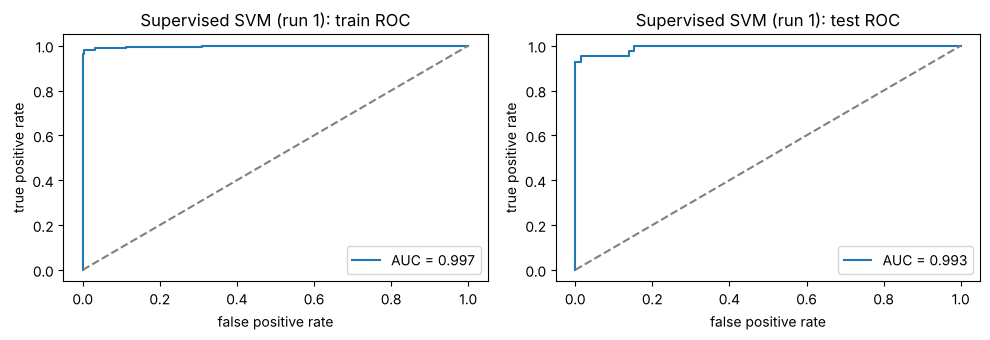

In [ ]:
show_run("Supervised SVM (run 1)", *saved["sup"])

ii. semi-supervised learning / self-training


In [ ]:
semi_results = []
for run in range(M):
    X_tr, X_te, y_tr, y_te = splits[run]
    lab_idx, unl_idx = train_test_split(np.arange(len(y_tr)), train_size=0.5, stratify=y_tr, random_state=run)

    search = GridSearchCV(l1_svm(), C_grid, cv=StratifiedKFold(5, shuffle=True, random_state=run))
    search.fit(X_tr[lab_idx], y_tr[lab_idx])
    best_C = search.best_params_["C"]

    X_lab, y_lab = X_tr[lab_idx], y_tr[lab_idx]
    X_unl = X_tr[unl_idx]
    svm = search.best_estimator_
    while len(X_unl) > 0:
        far = np.argmax(np.abs(svm.decision_function(X_unl)))
        X_lab = np.vstack([X_lab, X_unl[far]])
        y_lab = np.append(y_lab, svm.predict(X_unl[far:far + 1]))
        X_unl = np.delete(X_unl, far, axis=0)
        svm = LinearSVC(penalty="l1", dual=False, max_iter=20000, C=best_C).fit(X_lab, y_lab)

    for s, Xs, ys in [("train", X_tr, y_tr), ("test", X_te, y_te)]:
        semi_results.append({"set": s, **scores(ys, svm.predict(Xs), svm.decision_function(Xs))})
    if run == 0:
        saved["semi"] = (y_tr, svm.predict(X_tr), svm.decision_function(X_tr),
                         y_te, svm.predict(X_te), svm.decision_function(X_te))

semi_avg = average(semi_results)
semi_avg

,accuracy,precision,recall,f1,auc
set,,,,,
train,0.976117,0.981885,0.953922,0.967558,0.995077
test,0.964327,0.970279,0.932540,0.950510,0.992130


train confusion matrix (rows = actual B/M, cols = predicted B/M):
[[283   2]
 [  9 161]] 

test confusion matrix (rows = actual B/M, cols = predicted B/M):
[[69  3]
 [ 3 39]] 



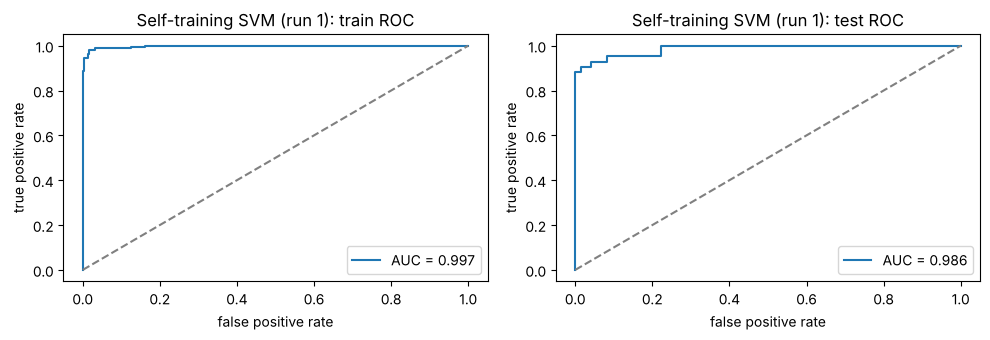

In [ ]:
show_run("Self-training SVM (run 1)", *saved["semi"])

iii. unsupervised learning: k-means (k = 2)

A. We ensure that the algorithm is not trapped in a local minimum here by running k-means k-means with 10 random initializations (init="random", n_init=10); the run with the lowest within-cluster sum of squares (inertia) is kept.


In [ ]:
def kmeans_proba(dist, cluster_label):
    p = np.exp(-dist) / np.exp(-dist).sum(axis=1, keepdims=True)
    return p[:, cluster_label == 1].sum(axis=1)

km_results = []
for run in range(M):
    X_tr, X_te, y_tr, y_te = splits[run]
    km = KMeans(n_clusters=2, init="random", n_init=10, random_state=run).fit(X_tr)

    dist_tr = km.transform(X_tr)
    cluster_label = np.array([np.bincount(y_tr[np.argsort(dist_tr[:, c])[:30]], minlength=2).argmax()
                              for c in range(2)])

    pred_tr = cluster_label[km.labels_]
    pred_te = cluster_label[km.predict(X_te)]
    score_tr = kmeans_proba(dist_tr, cluster_label)
    score_te = kmeans_proba(km.transform(X_te), cluster_label)

    km_results.append({"set": "train", **scores(y_tr, pred_tr, score_tr)})
    km_results.append({"set": "test", **scores(y_te, pred_te, score_te)})
    if run == 0:
        saved["km"] = (y_tr, pred_tr, score_tr, y_te, pred_te, score_te)

km_avg = average(km_results)
km_avg

,accuracy,precision,recall,f1,auc
set,,,,,
train,0.910256,0.923690,0.828627,0.873381,0.974841
test,0.905556,0.909718,0.826984,0.865157,0.971836


train confusion matrix (rows = actual B/M, cols = predicted B/M):
[[277   8]
 [ 33 137]] 

test confusion matrix (rows = actual B/M, cols = predicted B/M):
[[65  7]
 [ 7 35]] 



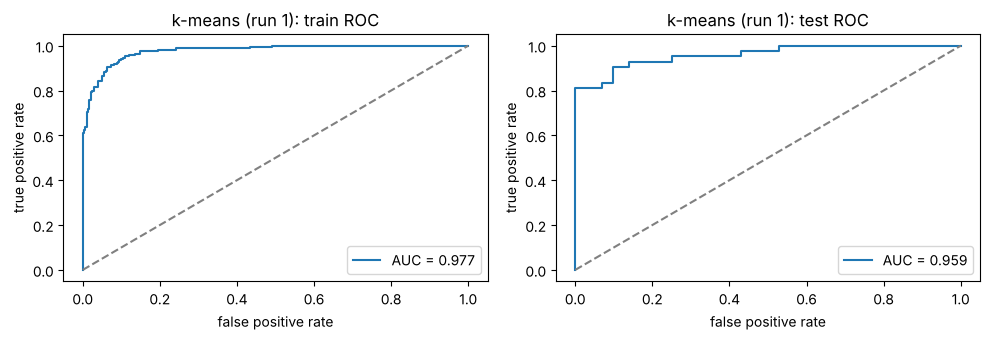

In [ ]:
show_run("k-means (run 1)", *saved["km"])

iv. spectral clustering

In [ ]:
gamma_grid = [0.001, 0.003, 0.01, 0.02, 0.03, 0.05, 0.1]

def spectral(X_fit, gamma, seed):
    return SpectralClustering(n_clusters=2, affinity="rbf", gamma=gamma, random_state=seed).fit_predict(X_fit)

def label_clusters(clusters, y_known):
    share = np.array([y_known[clusters == c].mean() if (clusters == c).any() else 0 for c in range(2)])
    return (share > 0.5).astype(int), share

sc_results, chosen_gammas = [], []
for run in range(M):
    X_tr, X_te, y_tr, y_te = splits[run]

    best_gamma = min(gamma_grid, key=lambda g: abs(np.bincount(spectral(X_tr, g, run), minlength=2).min() - y_tr.sum()))
    chosen_gammas.append(best_gamma)

    cl_tr = spectral(X_tr, best_gamma, run)
    cluster_label, share = label_clusters(cl_tr, y_tr)
    pred_tr, score_tr = cluster_label[cl_tr], share[cl_tr]

    cl_all = spectral(np.vstack([X_tr, X_te]), best_gamma, run)
    cluster_label_all, share_all = label_clusters(cl_all[:len(y_tr)], y_tr)
    cl_te = cl_all[len(y_tr):]
    pred_te, score_te = cluster_label_all[cl_te], share_all[cl_te]

    sc_results.append({"set": "train", **scores(y_tr, pred_tr, score_tr)})
    sc_results.append({"set": "test", **scores(y_te, pred_te, score_te)})
    if run == 0:
        saved["sc"] = (y_tr, pred_tr, score_tr, y_te, pred_te, score_te)

print("gammas chosen:", pd.Series(chosen_gammas).value_counts().to_dict())
sc_avg = average(sc_results)
sc_avg

gammas chosen: {0.001: 30}


,accuracy,precision,recall,f1,auc
set,,,,,
train,0.908864,0.926860,0.821176,0.870588,0.891173
test,0.907310,0.919477,0.822222,0.866783,0.889583


train confusion matrix (rows = actual B/M, cols = predicted B/M):
[[277   8]
 [ 33 137]] 

test confusion matrix (rows = actual B/M, cols = predicted B/M):
[[66  6]
 [ 5 37]] 



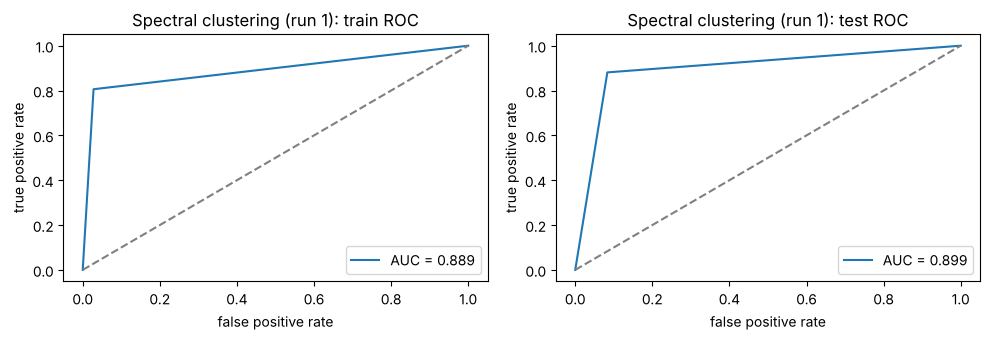

In [ ]:
show_run("Spectral clustering (run 1)", *saved["sc"])

v. compare results

In [ ]:
comparison = pd.concat({"supervised SVM": sup_avg.loc["test"], "self-training SVM": semi_avg.loc["test"],
                        "k-means": km_avg.loc["test"], "spectral clustering": sc_avg.loc["test"]}, axis=1).T
comparison.round(3)

,accuracy,precision,recall,f1,auc
supervised SVM,0.968,0.974,0.939,0.955,0.993
self-training SVM,0.964,0.970,0.933,0.951,0.992
k-means,0.906,0.910,0.827,0.865,0.972
spectral clustering,0.907,0.919,0.822,0.867,0.890


Analyzing the results:
- Supervised SVM is the strongest - (test accuracy 96.8%, F1 0.955, AUC 0.993) as it uses all the training labels.
- Self-training is almost as strong- (96.4%, F1 0.951, AUC 0.992) with only half the labels. The pseudo-labels it adds are mostly correct, because it always labels the points that it's most confident about first.
- Both clustering methods are substantially worse (about 90.6% accuracy, F1 about 0.87); they do not use labels to form clusters so they miss more malignant cases: about 17% of malignant tumors end up in the "benign" cluster.
- Spectral clustering performs roughly the same as k-means. Its AUC is lower only because its score has just two values (one per cluster) so its ROC curve is a single point.

### 2a. load banknote data

In [ ]:
bank = pd.read_csv("../data/data_banknote_authentication.txt", header=None,
                   names=["variance", "skewness", "curtosis", "entropy", "class"])
Xb = bank.iloc[:, :4].values
yb = bank["class"].values

Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=472, random_state=RANDOM_STATE)
scaler_b = StandardScaler().fit(Xb_tr)
Xb_tr, Xb_te = scaler_b.transform(Xb_tr), scaler_b.transform(Xb_te)
print("train:", Xb_tr.shape, "test:", Xb_te.shape)

train: (900, 4) test: (472, 4)


### 2b. incremental SVM training

In [ ]:
bank_C = [0.01, 0.1, 1, 10, 100]

def fit_cv_svm(Xp, yp, seed):
    n_splits = min(5, np.bincount(yp).min())
    cv = StratifiedKFold(n_splits, shuffle=True, random_state=seed)
    best_C, best_acc = None, -1
    for C in bank_C:
        accs = []
        for tr, va in cv.split(Xp, yp):
            m = LinearSVC(penalty="l1", dual=False, max_iter=20000, C=C).fit(Xp[tr], yp[tr])
            accs.append((m.predict(Xp[va]) == yp[va]).mean())
        if np.mean(accs) > best_acc:
            best_C, best_acc = C, np.mean(accs)
    return LinearSVC(penalty="l1", dual=False, max_iter=20000, C=best_C).fit(Xp, yp)

def first_pool(rng):
    while True:
        idx = rng.choice(len(yb_tr), 10, replace=False)
        if np.bincount(yb_tr[idx], minlength=2).min() >= 2:
            return idx

def learning_curve(active, seed):
    rng = np.random.default_rng(seed)
    pool = list(first_pool(rng))
    remaining = [i for i in rng.permutation(len(yb_tr)) if i not in set(pool)]
    errors = []
    while True:
        svm = fit_cv_svm(Xb_tr[pool], yb_tr[pool], seed)
        errors.append(1 - (svm.predict(Xb_te) == yb_te).mean())
        if not remaining:
            return errors
        if active:
            dist = np.abs(svm.decision_function(Xb_tr[remaining]))
            pick = [remaining[i] for i in np.argsort(dist)[:10]]
        else:
            pick = remaining[:10]
        pool += pick
        remaining = [i for i in remaining if i not in set(pick)]

passive = np.array([learning_curve(False, s) for s in range(50)])
active = np.array([learning_curve(True, s) for s in range(50)])
print(passive.shape, active.shape)

(50, 90) (50, 90)


### 2c. learning curves

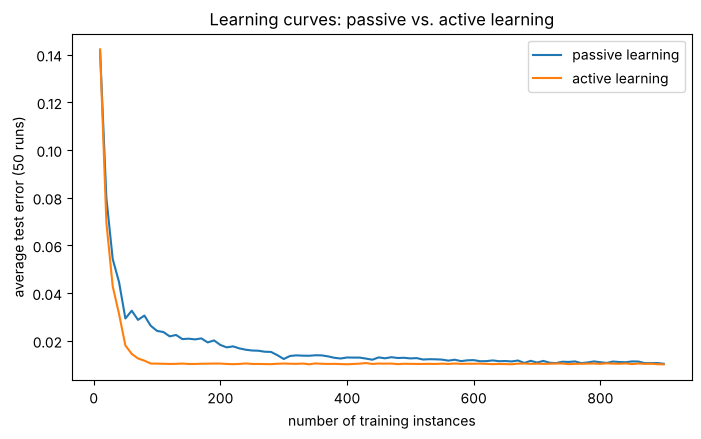

average test error at 10 / 50 / 100 / 900 points:


,passive,active
10,0.1418,0.1422
50,0.0294,0.0181
100,0.0242,0.0104
900,0.0104,0.0101


In [ ]:
n_points = np.arange(10, 901, 10)
plt.figure(figsize=(8, 4.5))
plt.plot(n_points, passive.mean(axis=0), label="passive learning")
plt.plot(n_points, active.mean(axis=0), label="active learning")
plt.xlabel("number of training instances"); plt.ylabel("average test error (50 runs)")
plt.title("Learning curves: passive vs. active learning")
plt.legend(); plt.show()

print("average test error at 10 / 50 / 100 / 900 points:")
pd.DataFrame({"passive": passive.mean(axis=0), "active": active.mean(axis=0)}, index=n_points).loc[[10, 50, 100, 900]].round(4)

Conclusion: Both learners start around 14% error with 10 points and end around 1% with all 900. Active learning drops much faster: at 100 points it's at 1.0% vs. 2.4% for passive, so it reaches its final error with far fewer points. Points near the hyperplane are the ones the SVM is least sure about, so adding them helps more than adding random points.